<a href="https://colab.research.google.com/github/Hesandu-Ruwanpathirana/telco-customer-churn-prediction/blob/main/churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Telco Customer Churn Prediction
## 1. Loading and Inspecting the Data

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


# Makes the charts look cleaner
sns.set_style("whitegrid")

In [3]:
url = "https://raw.githubusercontent.com/Hesandu-Ruwanpathirana/telco-customer-churn-prediction/main/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# Shows how many rows and columns we have
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
# Finds rows where TotalCharges is just a blank space
blank_rows = df[df["TotalCharges"] == " "]
print("Blank TotalCharges rows:", len(blank_rows))
blank_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Blank TotalCharges rows: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


**Section 1 findings:**
- The dataset contains 7,043 customers and 21 columns.
- Each row is one customer, with information on demographics (gender, SeniorCitizen, Partner, Dependents), account details (tenure, Contract, PaymentMethod, PaperlessBilling, MonthlyCharges, TotalCharges) and services (PhoneService, InternetService, OnlineSecurity, TechSupport, StreamingTV, etc.).
- The target variable is Churn (Yes/No), indicating whether the customer left within the last month.
- Most columns are categorical (text), so they will need to be converted to numbers before modelling.
- TotalCharges was stored as text (object) instead of a number. Investigation showed 11 rows containing a blank space instead of a value.
- All 11 of these customers have a tenure of 0, meaning they are new customers who have not yet been billed.

## 2. Data Cleaning

In [6]:
# Replaces blank spaces with 0 because these customers have tenure 0
df["TotalCharges"] = df["TotalCharges"].replace(" ", "0")

# Converts the column from text to a number
df["TotalCharges"] = df["TotalCharges"].astype(float)

print(df["TotalCharges"].dtype)

float64


In [7]:
# Removes the ID column since it has no predictive value
df = df.drop(columns=["customerID"])

print(df.shape)

(7043, 20)


In [8]:
# Counts missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

# Counts fully repeated rows
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 22


In [9]:
# Shows how many customers churned vs stayed
print(df["Churn"].value_counts())
print()
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


**Section 2 findings:**
- The 11 blank TotalCharges values were replaced with 0, since these customers have tenure 0 and have not been charged yet. TotalCharges was then converted to a numeric (float) type.
- customerID was removed because it is a unique identifier with no predictive value.
- After cleaning, there are no missing values in any column. The blank values were not detected by isnull() because they were stored as a space character rather than as empty values.
- 22 duplicate rows were found after removing customerID. These were kept, as they represent different customers who happen to share identical attributes rather than data-entry errors.
- The target is imbalanced: 5,174 customers (73.5%) did not churn and 1,869 (26.5%) did. A model predicting "No" for everyone would reach 73.5% accuracy while catching no churners, so recall, F1-score and ROC-AUC will be used alongside accuracy, together with stratified splitting and class weighting.

## 3. Exploratory Data Analysis

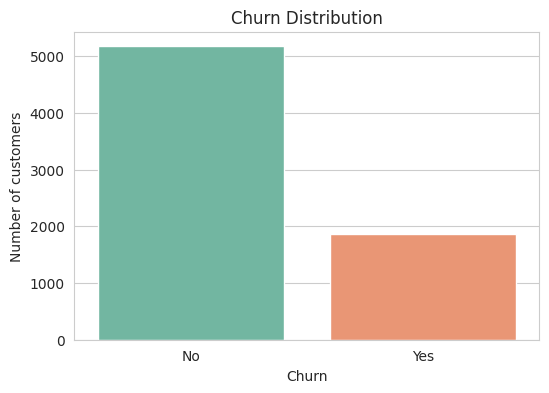

In [10]:
# Bar chart of how many customers churned vs stayed
plt.figure(figsize=(6, 4))
sns.countplot(x="Churn",hue = "Churn" , data=df, palette="Set2")
plt.title("Churn Distribution")
plt.ylabel("Number of customers")
plt.show()

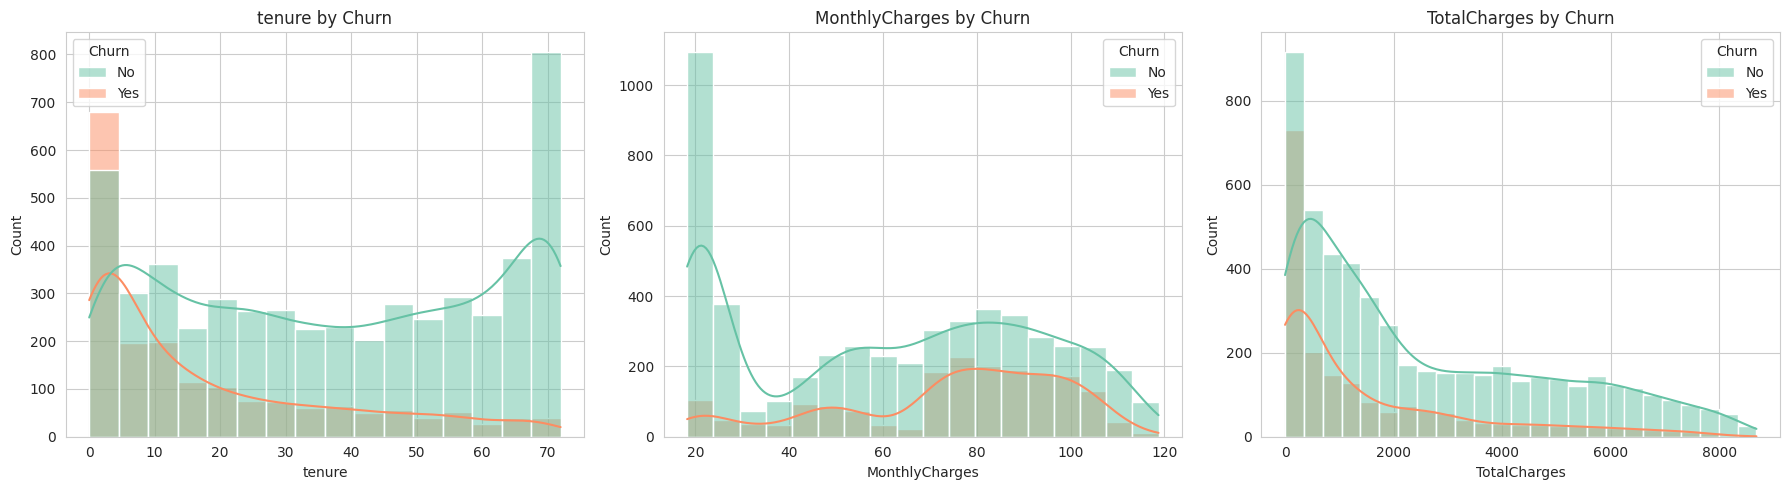

In [11]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

# One histogram per number column, coloured by churn
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i in range(len(num_cols)):
    col = num_cols[i]
    sns.histplot(data=df, x=col, hue="Churn", kde=True, ax=axes[i], palette="Set2")
    axes[i].set_title(col + " by Churn")
plt.tight_layout()
plt.show()


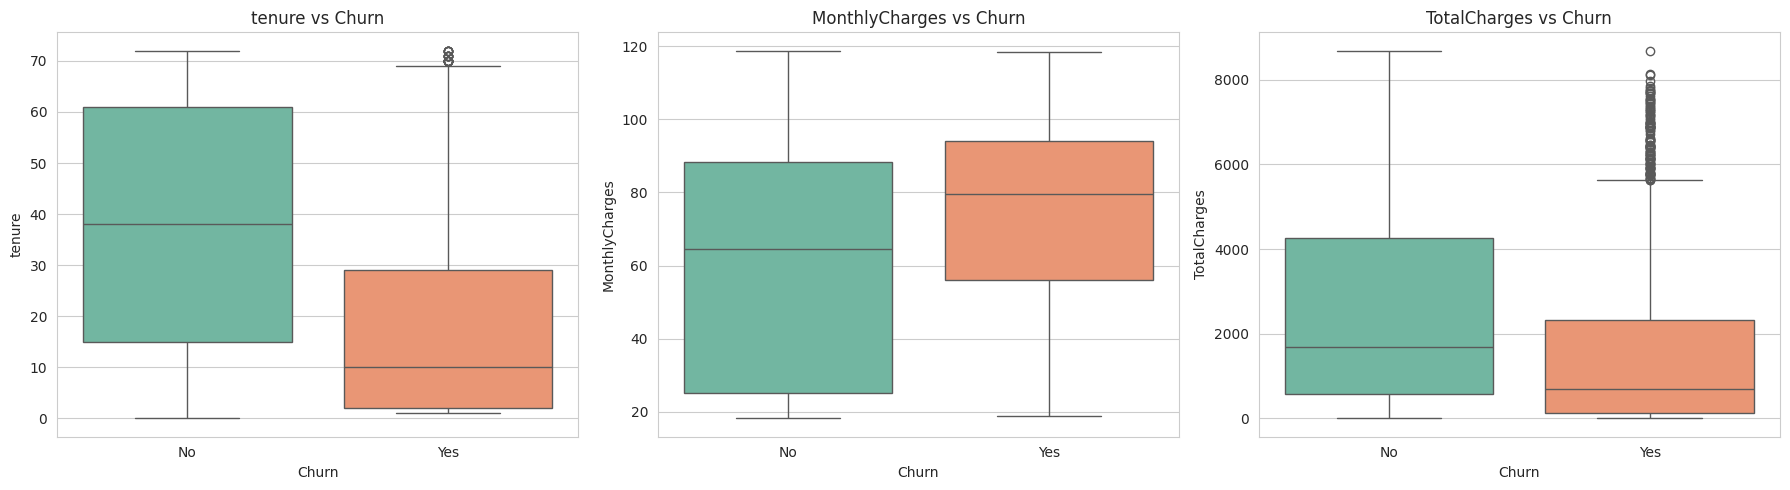

In [12]:
# Box plots comparing churners vs non-churners
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i in range(len(num_cols)):
    col = num_cols[i]
    sns.boxplot(data=df, x="Churn", y=col, hue="Churn", legend=False, ax=axes[i], palette="Set2")
    axes[i].set_title(col + " vs Churn")
plt.tight_layout()
plt.show()

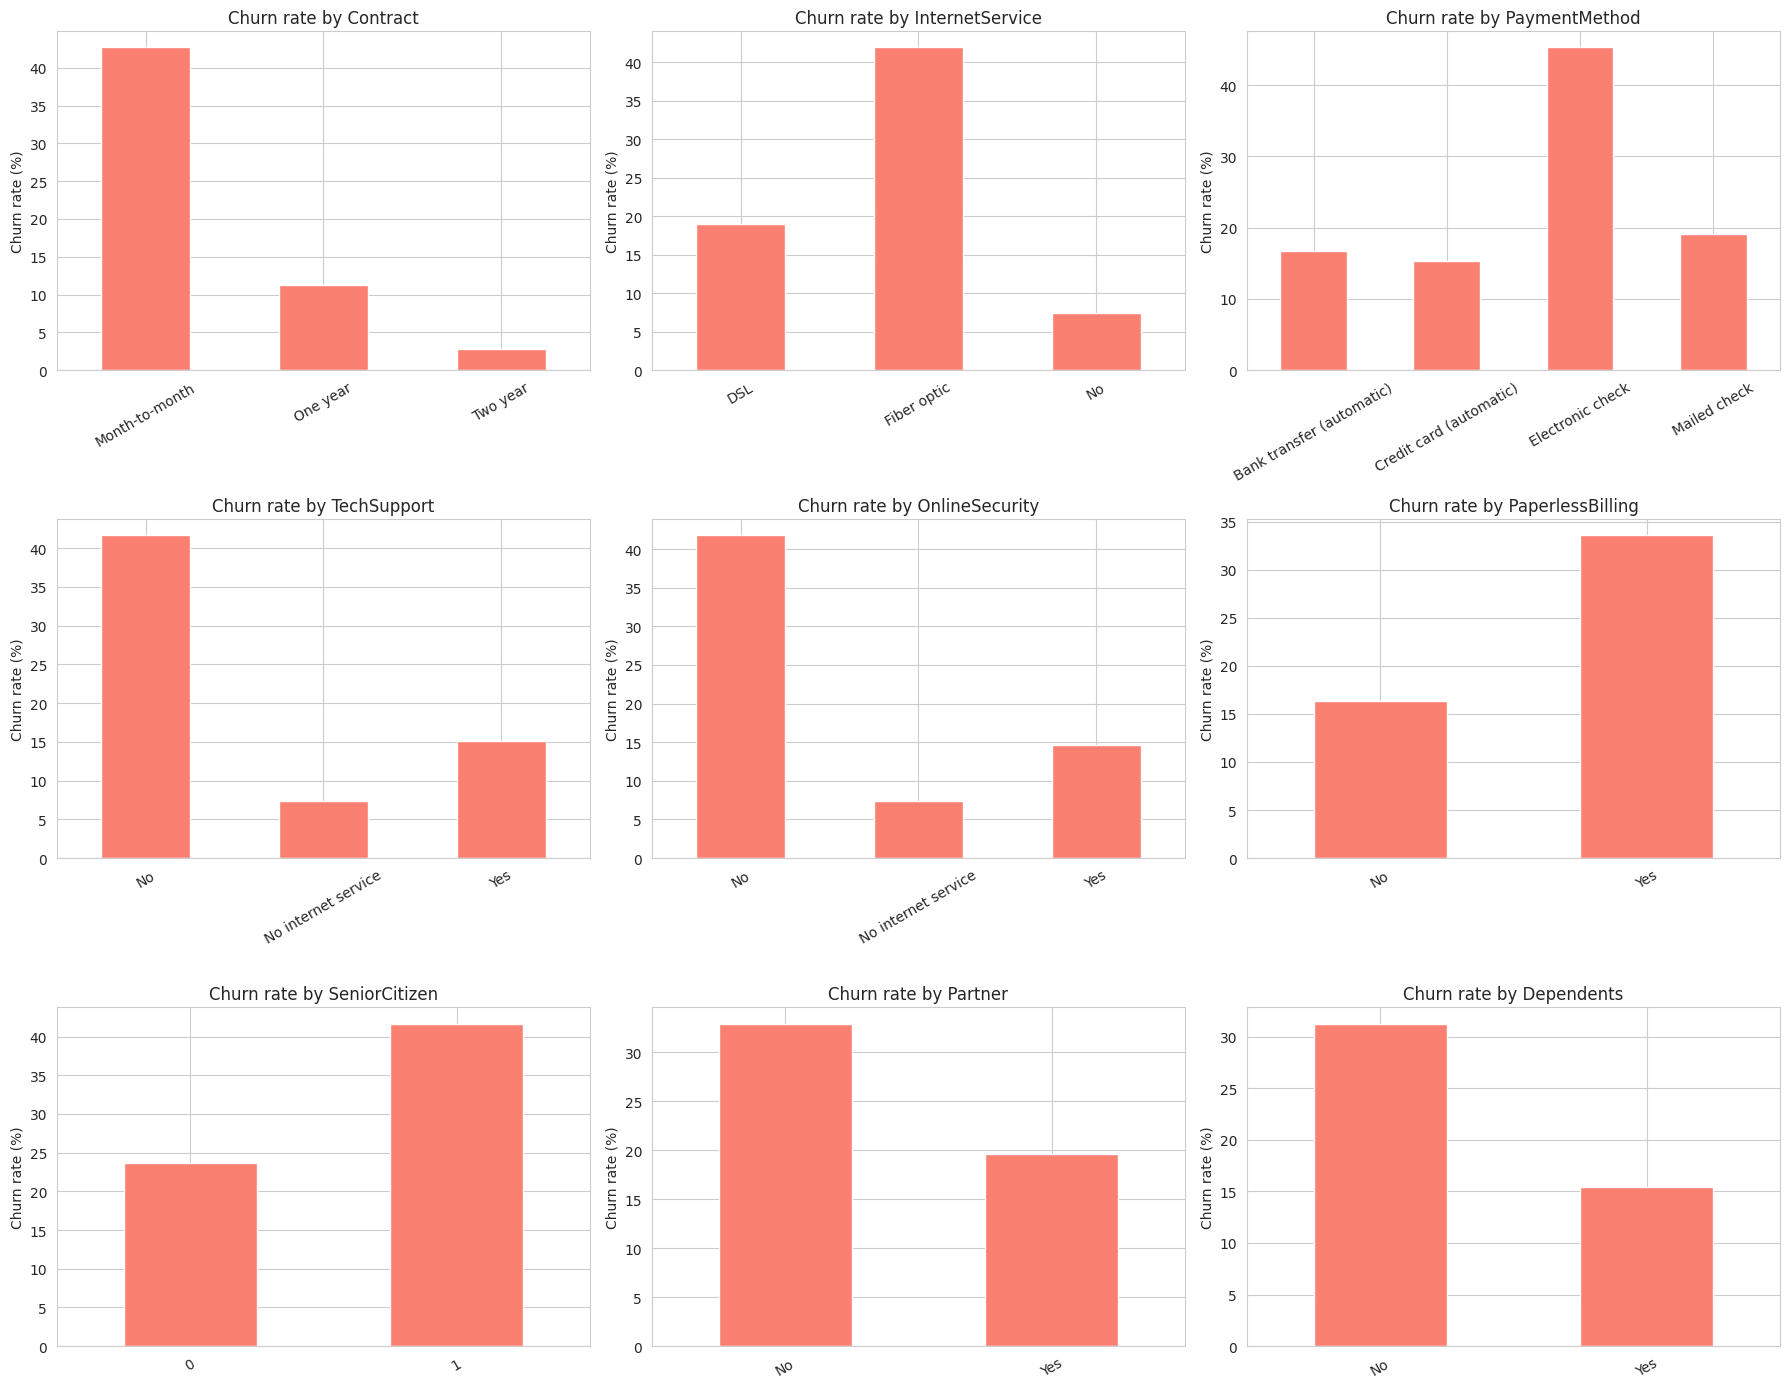

In [13]:
cat_cols = ["Contract", "InternetService", "PaymentMethod",
            "TechSupport", "OnlineSecurity", "PaperlessBilling",
            "SeniorCitizen", "Partner", "Dependents"]

# Churn rate (%) for each group in each category
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()
for i in range(len(cat_cols)):
    col = cat_cols[i]
    rates = pd.crosstab(df[col], df["Churn"], normalize="index") * 100
    rates["Yes"].plot(kind="bar", ax=axes[i], color="salmon")
    axes[i].set_title("Churn rate by " + col)
    axes[i].set_ylabel("Churn rate (%)")
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

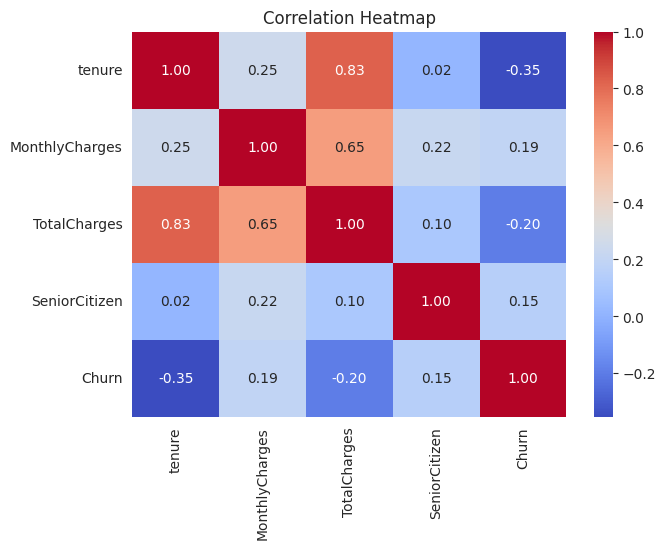

In [14]:
# Copies the number columns and adds churn as 1 or 0
corr_df = df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]].copy()
corr_df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

plt.figure(figsize=(7, 5))
sns.heatmap(corr_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

**Key EDA insights:**
1. The target is imbalanced (~73% No, ~27% Yes), so recall, F1 and ROC-AUC will be used alongside accuracy.
2. Contract type is the strongest indicator: month-to-month customers churn at ~43% vs ~3% for two-year contracts.
3. New customers are the highest risk: churners have a median tenure of ~10 months vs ~38 for non-churners.
4. Fiber optic users, electronic check payers, and customers without tech support or online security churn far more.
5. Higher monthly charges are associated with higher churn.
6. TotalCharges is highly correlated with tenure (r ≈ 0.83), indicating multicollinearity.

## 4. Data Preprocessing

In [15]:
# Copy of the cleaned data for modelling
data = df.copy()

# Turns Churn into 1 for Yes and 0 for No
data["Churn"] = data["Churn"].map({"Yes": 1, "No": 0})

# X is everything except Churn, y is just Churn
X = data.drop(columns=["Churn"])
y = data["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 19)
y shape: (7043,)


In [16]:
# Turns every text column into 0/1 columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("X shape after encoding:", X.shape)
X.head()

X shape after encoding: (7043, 30)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


In [17]:
from sklearn.model_selection import train_test_split

# Splits into 80% training and 20% testing, keeping the churn ratio the same
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("\nChurn % in training:", round(y_train.mean() * 100, 2))
print("Churn % in test:", round(y_test.mean() * 100, 2))

Training set: (5634, 30)
Test set: (1409, 30)

Churn % in training: 26.54
Churn % in test: 26.54


The data was split into 80% training (5,634 customers) and 20% test (1,409 customers) sets using train_test_split with stratify=y, ensuring both sets kept the original ~26.54% churn rate. random_state=42 was set so the split is reproducible. The test set was held out and used only for final evaluation.

In [18]:
from sklearn.preprocessing import StandardScaler

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

scaler = StandardScaler()

# Learns the average and spread from training data, then scales it
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])

# Uses the training average and spread to scale test data
X_test[num_cols] = scaler.transform(X_test[num_cols])

X_train[num_cols].describe().round(2)


,tenure,MonthlyCharges,TotalCharges
count,5634.00,5634.00,5634.00
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-1.32,-1.54,-1.01
25%,-0.96,-0.97,-0.83
50%,-0.14,0.18,-0.40
75%,0.92,0.83,0.67
max,1.61,1.79,2.80


**Section 4 findings:**
- Churn was converted to 1 (Yes) and 0 (No) and separated as the target (y); the remaining 19 columns formed the features (X).
- Categorical features were one-hot encoded with drop_first=True. Each category became a binary (0/1) column, avoiding a false numerical order between categories. One column per feature was dropped because it can be inferred from the others; the dropped group becomes the baseline, which removes redundancy and prevents multicollinearity in Logistic Regression. Features increased from 19 to 30.
- The data was split 80/20 into training (5,634) and test (1,409) sets with stratify=y, so both sets kept the same 26.54% churn rate. random_state=42 ensures the split is reproducible. The test set is held out and used only for final evaluation.
- tenure, MonthlyCharges and TotalCharges were standardised with StandardScaler. After scaling, the training set had mean 0 and standard deviation 1 for all three, confirming the transformation worked, with no rows lost (count 5,634). The scaler was fitted on the training set only and then applied to the test set, preventing data leakage.
- Scaling changes the units but not the shape of the data: TotalCharges remains right-skewed (median -0.40, max 2.80).

## 5. Logistic Regression

In [19]:
from sklearn.linear_model import LogisticRegression

# Creates a Logistic Regression model with default settings
lr_base = LogisticRegression(max_iter=1000, random_state=42)

# Learns the weights from the training customers and their answers
lr_base.fit(X_train, y_train)

# Predicts the probability of churn for the test customers
y_prob_lr_base = lr_base.predict_proba(X_test)[:, 1]

# Predicts churn (1 or 0) for the test customers
y_pred_lr_base = lr_base.predict(X_test)


print("Model trained.")
print("First 10 predictions:", y_pred_lr_base[:10])
print("First 10 probabilities:", y_prob_lr_base[:10].round(2))

Model trained.
First 10 predictions: [0 1 0 0 0 1 0 0 0 0]
First 10 probabilities: [0.05 0.68 0.06 0.4  0.02 0.6  0.45 0.13 0.   0.4 ]


In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report

# Calculates each metric by comparing predictions with the real answers
print("Accuracy :", round(accuracy_score(y_test, y_pred_lr_base), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr_base), 4))
print("Recall   :", round(recall_score(y_test, y_pred_lr_base), 4))
print("F1-score :", round(f1_score(y_test, y_pred_lr_base), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_lr_base), 4))

# Full report for both classes
print("\n", classification_report(y_test, y_pred_lr_base, target_names=["No Churn", "Churn"]))

Accuracy : 0.8062
Precision: 0.6593
Recall   : 0.5588
F1-score : 0.6049
ROC-AUC  : 0.8422

               precision    recall  f1-score   support

    No Churn       0.85      0.90      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



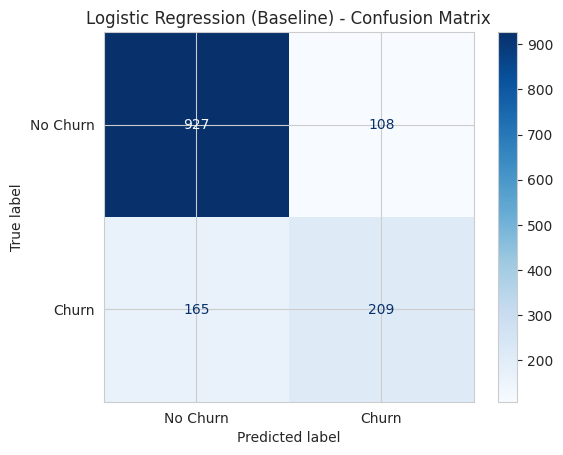

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay

# Draws the 4-box table of correct and wrong predictions
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr_base, display_labels=["No Churn", "Churn"], cmap="Blues")
plt.title("Logistic Regression (Baseline) - Confusion Matrix")
plt.show()

The confusion matrix shows the baseline model correctly classified 927 non-churners and 209 churners, but missed 165 churners (false negatives) and raised 108 false alarms (false positives). Missed churners are the more costly error for the business, since these customers leave without any retention attempt, whereas a false alarm only costs an unnecessary retention offer. Reducing false negatives is therefore the main goal of tuning.

### Hyperparameter Tuning

In [28]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Settings to try for Logistic Regression
param_grid_lr = {
    "C": [0.01, 0.1, 1, 10, 100],
    "class_weight": [None, "balanced"]
}

# 5-fold cross-validation that keeps the churn ratio in every fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Tries every combination and scores each one with F1
grid_lr = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    param_grid_lr,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

# Runs the search on the training data only
grid_lr.fit(X_train, y_train)

print("Best settings:", grid_lr.best_params_)
print("Best cross-validation F1:", round(grid_lr.best_score_, 4))

# The best model, already retrained on all training data
lr_tuned = grid_lr.best_estimator_

Best settings: {'C': 0.1, 'class_weight': 'balanced'}
Best cross-validation F1: 0.6301


In [29]:
# Table of every combination tried and its average CV F1
results_lr = pd.DataFrame(grid_lr.cv_results_)
results_lr = results_lr[["param_C", "param_class_weight", "mean_test_score"]]
results_lr = results_lr.sort_values("mean_test_score", ascending=False)
results_lr.round(4)

,param_C,param_class_weight,mean_test_score
3,0.10,balanced,0.6301
5,1.00,balanced,0.6296
7,10.00,balanced,0.6274
1,0.01,balanced,0.6272
9,100.00,balanced,0.6271
6,10.00,None,0.5978
8,100.00,None,0.5974
4,1.00,None,0.5936
2,0.10,None,0.5894
0,0.01,None,0.5638


In [30]:
# Calculates the 5 metrics for one model and returns them together
def get_scores(y_true, y_pred, y_prob):
    scores = {
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Precision": round(precision_score(y_true, y_pred), 4),
        "Recall": round(recall_score(y_true, y_pred), 4),
        "F1": round(f1_score(y_true, y_pred), 4),
        "ROC-AUC": round(roc_auc_score(y_true, y_prob), 4)
    }
    return scores

In [31]:
# Predicts with the tuned model on the test customers
y_pred_lr_tuned = lr_tuned.predict(X_test)
y_prob_lr_tuned = lr_tuned.predict_proba(X_test)[:, 1]

# Gets the metrics for both versions
lr_base_scores = get_scores(y_test, y_pred_lr_base, y_prob_lr_base)
lr_tuned_scores = get_scores(y_test, y_pred_lr_tuned, y_prob_lr_tuned)

# Puts baseline and tuned side by side
lr_comparison = pd.DataFrame([lr_base_scores, lr_tuned_scores],
                             index=["LR Baseline", "LR Tuned"])
lr_comparison

,Accuracy,Precision,Recall,F1,ROC-AUC
LR Baseline,0.8062,0.6593,0.5588,0.6049,0.8422
LR Tuned,0.7431,0.5105,0.7834,0.6181,0.8413


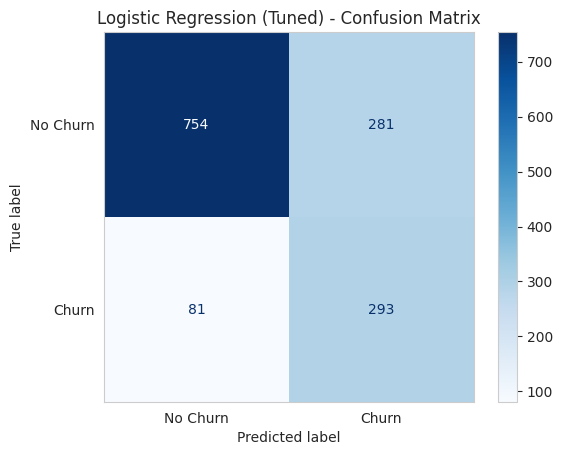

In [32]:
# Draws the 4-box table for the tuned model
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr_tuned,
                                        display_labels=["No Churn", "Churn"],
                                        cmap="Blues")
plt.title("Logistic Regression (Tuned) - Confusion Matrix")
plt.grid(False)
plt.show()

**Tuning findings:**
- Hyperparameters were tuned using GridSearchCV with stratified 5-fold cross-validation on the training set only, so the test set stayed untouched for final evaluation.
- Two hyperparameters were searched: C (regularisation strength: 0.01, 0.1, 1, 10, 100) and class_weight (None or "balanced"), giving 10 combinations and 50 model fits.
- F1-score was used to select the best model because it balances precision and recall. Accuracy would favour the majority "No Churn" class, and recall alone could be maximised by predicting churn for everyone.
- The best combination was C = 0.1 and class_weight = "balanced", with a mean cross-validation F1 of 0.630.
- All five balanced settings (F1 0.627–0.630) outperformed all five unweighted settings (F1 0.564–0.598). This shows that handling class imbalance had a much larger effect than regularisation strength, which changed F1 by less than 0.003 once class weighting was applied.
- The weakest setting (C = 0.01, no class weighting) combined strong regularisation with no imbalance handling, leading to underfitting and poor detection of churners.
- The best model was automatically refitted on the full training set before being evaluated on the test set.